### 데이터 준비까지만 진행합니다.

In [4]:
# 이 셀을 복사 붙여넣
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

Text(0.5, 1.0, '샘플 군집 데이터셋')

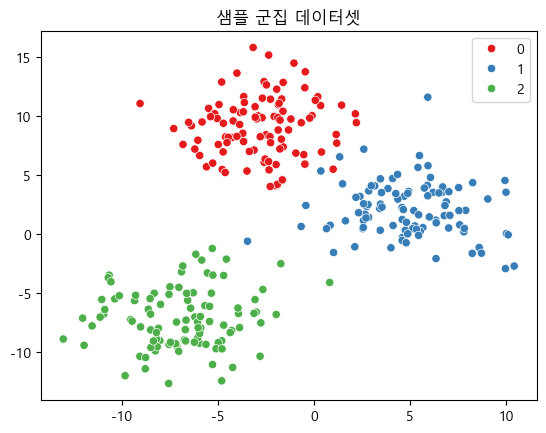

In [22]:
# 샘플 군집 생성하기 - 복붙
# 연습용 군집 데이터셋 생성하는 sklearn 라이브러리 함수
from sklearn.datasets import make_blobs
X, labels = make_blobs(n_samples=300, centers=3,
                      cluster_std=2.5,
                      random_state=42)

sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=labels, palette='Set1')
plt.title('샘플 군집 데이터셋')

<numpy 간단 이해>
- 차원
    * 스칼라(scalar, 0차원) - 값(value)
    * 벡터(vector, 1차원) - 시리즈(line)
    * 매트릭스(matrix, 2차원) - 행렬(table)
    * 텐서(tensor, 3차원) - 다차원 배열(N-dimensional Array)
- 명령어
    * X.ndim   # 차원 수
    * X.shape  # 형태
    * X.reshape(-1,1)   # 차원 재배열
    * X.mean(), X.std()   --- axis=0, 1인자 사용 가능

In [44]:
# 넘파이 array 이해
type(X)   # 출력 numpy.ndarray
X.ndim
X.shape   # 차원 확인 (300, 2) - 300개의 샘플, 2개의 특성

(300, 2)

In [61]:
# 다시 k-means를 이용한 군집분석
from sklearn.cluster import KMeans
km = KMeans(n_clusters=3, random_state=42)
km.fit(X)
label = km.labels_

<Axes: >

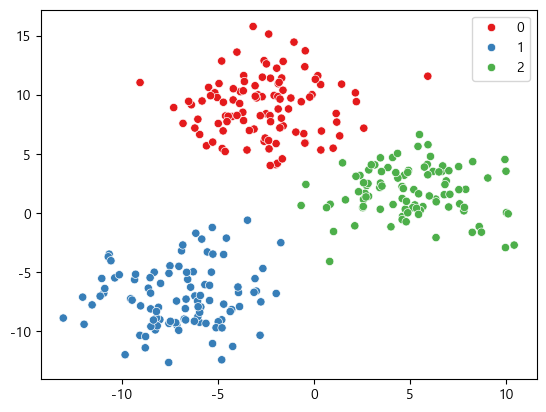

In [79]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=label, palette='Set1')
# 애당초 label이 없기 때문에, 맞느냐 틀리느냐를 따질 수는 없음

In [80]:
new_array = np.array([[-5, 0], [3, 3], [6, 6]]) # 새로운 샘플에 대한 군집 예측
new_pred = km.predict(new_array)

<Axes: >

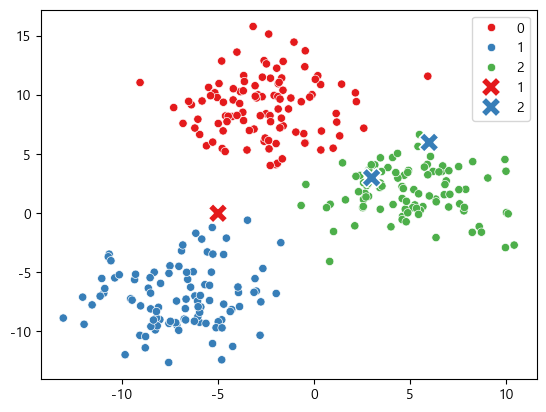

In [83]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=label, palette='Set1')
sns.scatterplot(x=new_array[:, 0], y=new_array[:, 1],
                hue=new_pred, palette='Set1', marker='X', s=200)
# 차트상 색이 다르기는 하나 같은 라벨로 예측

In [87]:
# k=2로 설정한다면?
# 다시 k-means를 이용한 군집분석
from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, random_state=42)
km.fit(X)
label = km.labels_

<Axes: >

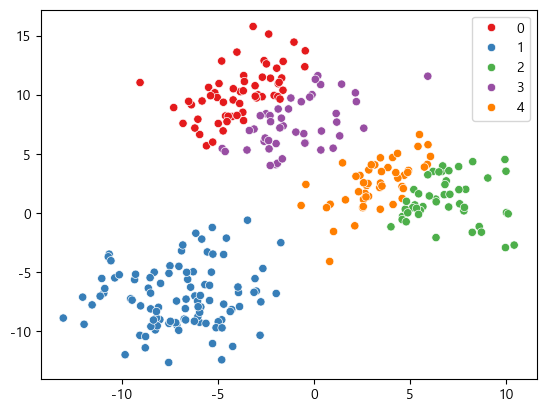

In [88]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=label, palette='Set1')
# k-means는 군집 수를 먼저 지정하고 그 숫자만큼 무조건 나눔

## 군집 수는 어떻게 정하나?
- 눈으로 볼때는 3개의 군집이 자명한 것 같음
- 다차원의 복잡한 데이터에서는 이를 미리 알기는 어려움
- 어떻게 적정한 k를 정할 수 있을까? 

In [96]:
# 실루엣 스코어 (silhouette_score)로 군집화 평가
# 군집 내 다른 원소와의 평균 거리와, 다른 군집의 평균 거리 차이를 집계한 값
from sklearn.metrics import silhouette_score
silhouette_score(X, label)

0.3142109112803241

Text(0.5, 1.0, 'k에 따른 실루엣 스코어 변화')

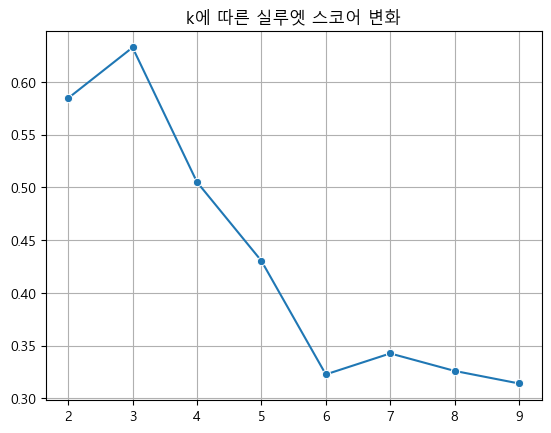

In [97]:
# k=2부터 9까지 for문을 이용해 실루엣 스코어를 계산하고 시각화
silhouette_scores = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    label = km.labels_
    score = silhouette_score(X, label)
    silhouette_scores.append(score)
sns.lineplot(x=range(2, 10), y=silhouette_scores, marker='o')
plt.grid(True)
plt.title('k에 따른 실루엣 스코어 변화')
# 실루엣스코어가 3에서 최대, 따라서 3으로 결정한다.

Text(0.5, 1.0, 'k에 따른 SSE 변화')

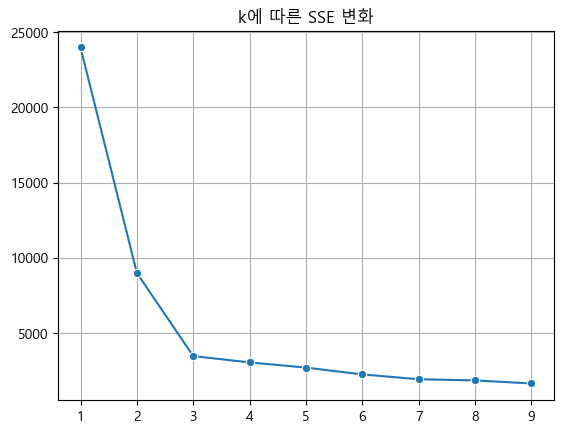

In [103]:
#SSE, 군집 내 오차제곱합(Sum of Squared Errors) 시각화
# km.inertia_ 사용

sse = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    sse.append(km.inertia_)
sns.lineplot(x=range(1, 10), y=sse, marker='o')
plt.grid(True)
plt.title('k에 따른 SSE 변화')
# 엘보우 방법
## SSE가 급격히 감소하다가 완만해지는 지점이 k=3, 따라서 3으로 결정한다.

# DBSCAN

<Axes: >

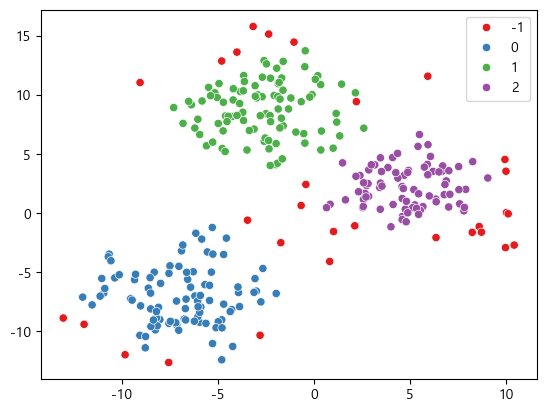

In [117]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan.fit(X)

sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=dbscan.labels_, palette='Set1')

<Axes: >

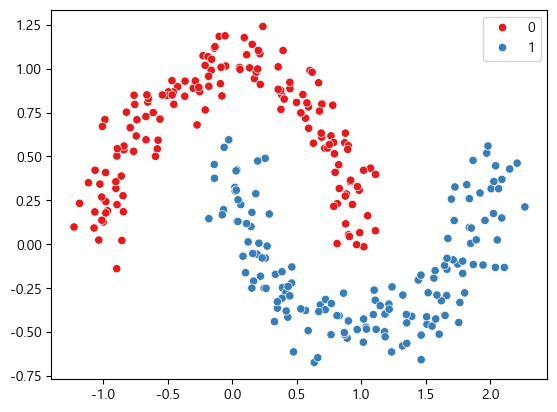

In [121]:
# db스캔은 언제 좋을까?
## moon dataset, circle dataset 등 비선형 데이터셋에서 군집화가 필요할 때
from sklearn.datasets import make_moons
X, label = make_moons(n_samples=300, noise=0.1, random_state=42)
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=label, palette='Set1')


<Axes: >

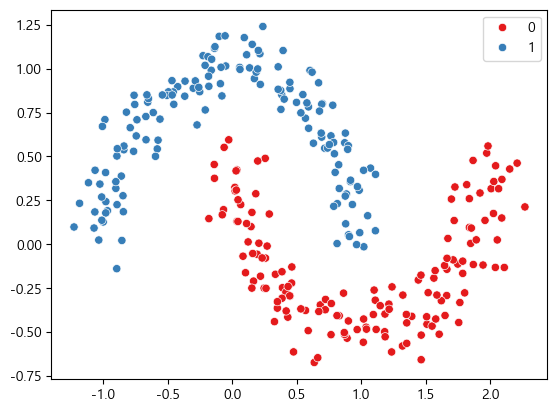

In [131]:
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X)
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=dbscan.labels_, palette='Set1')

<Axes: >

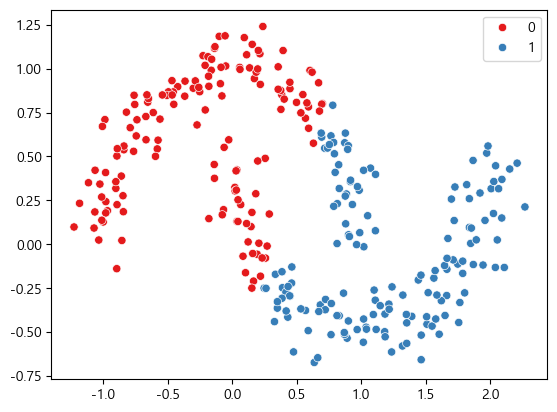

In [134]:
# kmeans를 적용해보면?
km = KMeans(n_clusters=2, random_state=42)
km.fit(X)
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=km.labels_, palette='Set1')

# 차원축소

In [161]:
# 롤케잌
from sklearn.datasets import make_swiss_roll
X, label = make_swiss_roll(n_samples=1000, noise=0, random_state=42)

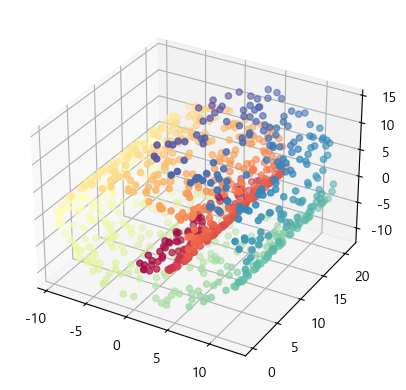

In [162]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=label, cmap='Spectral')
plt.show()

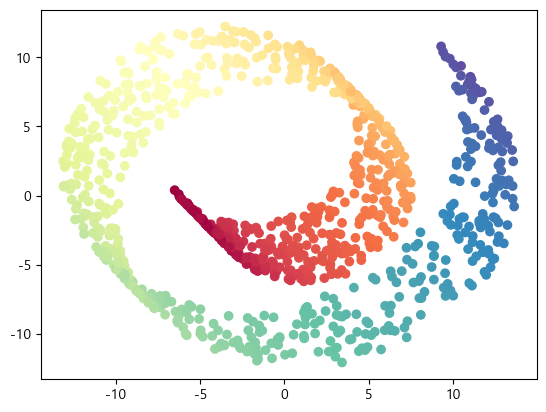

In [163]:
# pca는 자료의 요약
from sklearn.decomposition import PCA
pca = PCA(n_components=2)  # 2차원으로 축소
pca.fit(X)
X_pca = pca.transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=label, cmap='Spectral')

In [164]:
# pca의 주성분 확인
pca.components_

array([[ 0.57032387,  0.15839723,  0.8060031 ],
       [-0.78114429, -0.1988984 ,  0.59182178]])

In [165]:
pca.explained_variance_ratio_

array([0.40758356, 0.30260943])

In [188]:
# pca의 효과
from sklearn.datasets import make_blobs

X, labels = make_blobs(n_samples=300,
                      centers=3,
                      n_features=10,  # 10차원 데이터
                      cluster_std=5,
                      random_state=42)

<Axes: >

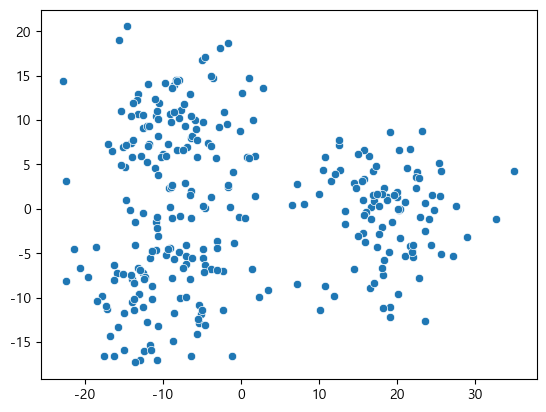

In [189]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1])

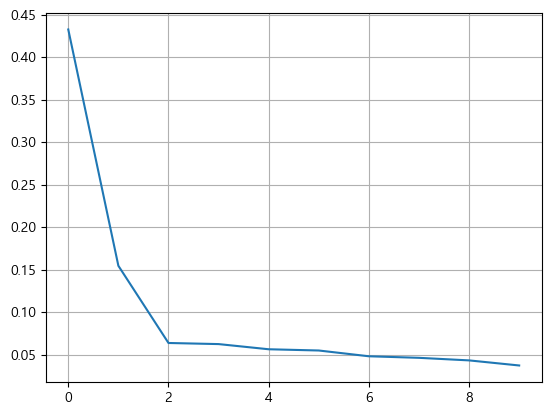

In [194]:
# pca를 설명하는 방법
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)
ratio = pca.explained_variance_ratio_
sns.lineplot(ratio)
plt.grid(True)

In [195]:
pca.explained_variance_ratio_

array([0.43262111, 0.15462539, 0.06378975, 0.06249062, 0.05640551,
       0.05494616, 0.04816036, 0.04632663, 0.04330797, 0.03732649])

<Axes: >

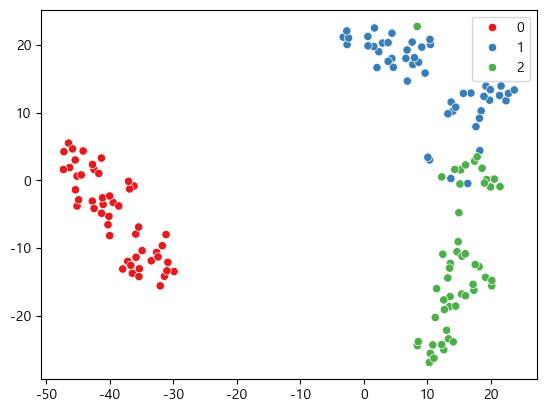

In [14]:
# t-sne
## 확률적 임베딩
from sklearn.datasets import load_iris
df = pd.DataFrame(load_iris().data)

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=10.0)  #perplexity=30.0 기본값
tsne = tsne.fit_transform(df)
sns.scatterplot(x=tsne[:,0], y=tsne[:,1],
                hue=load_iris().target, palette='Set1')

# 덴드로그램

In [24]:
from scipy.cluster.hierarchy import dendrogram, linkage
z = linkage(X, method='ward')

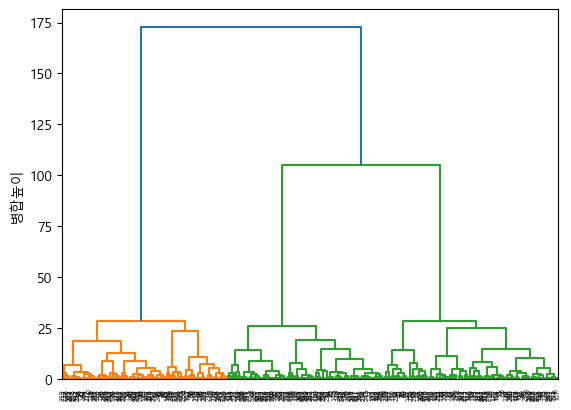

In [26]:
dendrogram(z)
plt.ylabel('병합높이')
plt.show()

# k-means 시각화

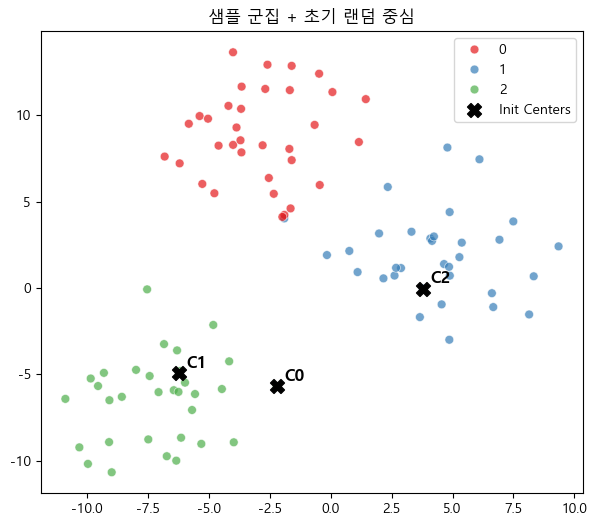

In [255]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

# 1. 샘플 군집 데이터 생성
X, clust = make_blobs(
    centers=3,
    cluster_std=2.5,
    random_state=42
)

# 2. 랜덤 초기 중심 3개 생성
np.random.seed(42)
init_centers = X[np.random.choice(len(X), size=3, replace=False)]

# 3. 시각화
plt.figure(figsize=(7, 6))

# 실제 데이터
sns.scatterplot(
    x=X[:, 0], y=X[:, 1],
    hue=clust, palette='Set1',
    s=40, alpha=0.7
)

# 초기 중심 (X 마커)
plt.scatter(
    init_centers[:, 0],
    init_centers[:, 1],
    marker='X',
    s=100,
    color='black',
    label='Init Centers'
)

# 라벨 표시
for i, (x, y) in enumerate(init_centers):
    plt.text(x + 0.3, y + 0.3, f'C{i}', fontsize=12, fontweight='bold')

plt.title('샘플 군집 + 초기 랜덤 중심')
plt.legend()
plt.show()


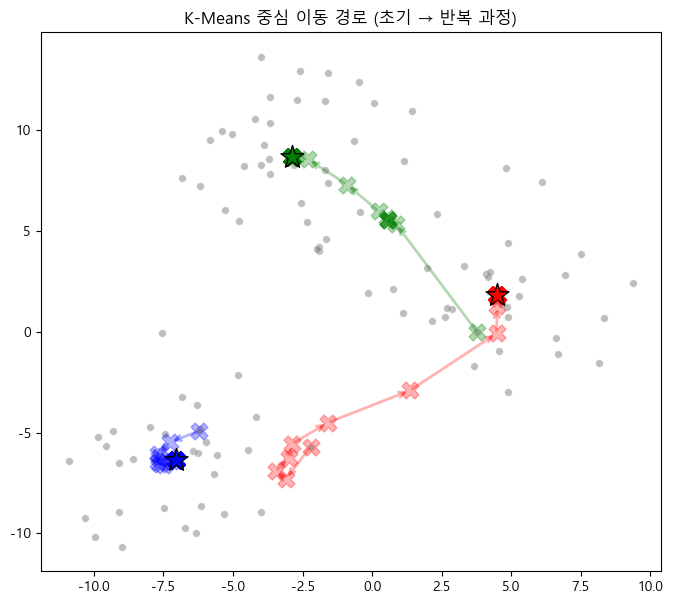

In [253]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

# 1. 데이터 생성
X, _ = make_blobs(centers=3, cluster_std=2.5, random_state=42)

# --------------------------------------------------------
# 2. k-means 초기화 + 수동 iteration 수행 (중심 이동 추적)
# --------------------------------------------------------

def run_kmeans_with_tracking(X, k=3, max_iter=5):
    np.random.seed(42)

    # 초기 중심 랜덤 선택
    centers = X[np.random.choice(len(X), size=k, replace=False)]
    history = [centers.copy()]  # 초기 중심 기록

    for it in range(max_iter):
        # 각 점을 가장 가까운 중심에 할당
        dists = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = np.argmin(dists, axis=1)

        # 중심 업데이트
        new_centers = np.array([X[labels == i].mean(axis=0) for i in range(k)])
        history.append(new_centers.copy())

        centers = new_centers

    return history

# 중심 이동 기록
history = run_kmeans_with_tracking(X, k=3, max_iter=50)

# --------------------------------------------------------
# 3. 시각화
# --------------------------------------------------------

plt.figure(figsize=(8, 7))

# 데이터 점
sns.scatterplot(x=X[:, 0], y=X[:, 1], color='gray', s=30, alpha=0.5)

colors = ['red', 'blue', 'green']

# iteration별 중심 이동 화살표 시각화
for c in range(3):  # 3개 클러스터
    for i in range(len(history) - 1):
        x_old, y_old = history[i][c]
        x_new, y_new = history[i + 1][c]

        plt.scatter(x_old, y_old, color=colors[c], marker='X', s=150, alpha=0.3)
        plt.annotate(
            "", 
            xy=(x_new, y_new), 
            xytext=(x_old, y_old),
            arrowprops=dict(arrowstyle="->", color=colors[c], lw=2, alpha=0.3)
        )

# 마지막 중심점 강조
for c in range(3):
    x_final, y_final = history[-1][c]
    plt.scatter(x_final, y_final, color=colors[c], marker='*', s=300, edgecolor='black')

plt.title("K-Means 중심 이동 경로 (초기 → 반복 과정)")
plt.show()


In [200]:
# 애니메이션 버전
import numpy as np
from sklearn.datasets import make_blobs

# 1. 데이터 생성
X, _ = make_blobs(centers=3, cluster_std=2.5, random_state=42)

# 2. k-means 수동 구현 (중심 이동 추적)
def run_kmeans_with_tracking(X, k=3, max_iter=50, random_state=42):
    rng = np.random.RandomState(random_state)
    centers = X[rng.choice(len(X), size=k, replace=False)]
    history_centers = [centers.copy()]
    history_labels = []

    for it in range(max_iter):
        # 거리 계산
        dists = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = np.argmin(dists, axis=1)
        history_labels.append(labels.copy())

        # 중심 업데이트
        new_centers = np.array([X[labels == i].mean(axis=0) for i in range(k)])
        history_centers.append(new_centers.copy())
        centers = new_centers

    return history_centers, history_labels

history_centers, history_labels = run_kmeans_with_tracking(X, k=3, max_iter=10)


In [201]:
import plotly.graph_objects as go
import plotly.express as px

k = 3
n_iter = len(history_centers) - 1  # 업데이트 횟수

# 색 팔레트
palette = px.colors.qualitative.Set1[:k]

# 초기 figure (iteration 0)
fig = go.Figure()

# 데이터 포인트 (초기에는 라벨 없음 -> 전부 회색)
fig.add_trace(go.Scatter(
    x=X[:, 0], y=X[:, 1],
    mode='markers',
    marker=dict(size=6, color='lightgray'),
    name='points'
))

# 초기 중심
init_centers = history_centers[0]
fig.add_trace(go.Scatter(
    x=init_centers[:, 0],
    y=init_centers[:, 1],
    mode='markers+text',
    marker=dict(size=16, symbol='x', color='black'),
    text=[f'C{j}' for j in range(k)],
    textposition='top center',
    name='centers (iter 0)'
))

# 프레임 생성
frames = []
for it in range(1, n_iter + 1):
    centers_prev = history_centers[it - 1]
    centers_curr = history_centers[it]
    labels = history_labels[it - 1]

    # 포인트 색은 해당 iteration의 라벨로 칠하기
    point_colors = [palette[l] for l in labels]

    # 포인트 trace
    points_trace = go.Scatter(
        x=X[:, 0],
        y=X[:, 1],
        mode='markers',
        marker=dict(size=6, color=point_colors, opacity=0.7),
        name=f'points (iter {it})',
        showlegend=False
    )

    # 현재 중심 trace
    centers_trace = go.Scatter(
        x=centers_curr[:, 0],
        y=centers_curr[:, 1],
        mode='markers+text',
        marker=dict(size=18, symbol='x', color='black', line=dict(width=2)),
        text=[f'C{j}' for j in range(k)],
        textposition='top center',
        name=f'centers (iter {it})',
        showlegend=False
    )

    # 화살표(이전 중심 → 현재 중심)
    arrows = []
    for j in range(k):
        x0, y0 = centers_prev[j]
        x1, y1 = centers_curr[j]
        arrows.append(
            dict(
                x=x1, y=y1,
                ax=x0, ay=y0,
                xref='x', yref='y',
                axref='x', ayref='y',
                showarrow=True,
                arrowhead=3,
                arrowsize=1,
                arrowwidth=2,
                arrowcolor=palette[j]
            )
        )

    frame = go.Frame(
        data=[points_trace, centers_trace],
        name=f'iter {it}',
        layout=go.Layout(
            title_text=f'K-Means 중심 이동 (iteration {it})',
            annotations=arrows
        )
    )
    frames.append(frame)

fig.frames = frames

# 레이아웃 + 슬라이더 / 버튼
fig.update_layout(
    title='K-Means 중심 이동 경로 (Plotly 애니메이션)',
    xaxis_title='X1',
    yaxis_title='X2',
    width=800,
    height=700,
    xaxis=dict(scaleanchor='y', scaleratio=1),
    updatemenus=[
        dict(
            type='buttons',
            showactive=False,
            x=1.05, y=1.15,
            buttons=[
                dict(
                    label='▶ Play',
                    method='animate',
                    args=[None, {
                        'frame': {'duration': 800, 'redraw': True},
                        'fromcurrent': True,
                        'transition': {'duration': 300}
                    }]
                ),
                dict(
                    label='⏸ Pause',
                    method='animate',
                    args=[[None], {
                        'frame': {'duration': 0, 'redraw': False},
                        'mode': 'immediate',
                        'transition': {'duration': 0}
                    }]
                )
            ]
        )
    ],
    sliders=[
        dict(
            steps=[
                dict(
                    method='animate',
                    label=f'{i}',
                    args=[[f'iter {i}'], {
                        'frame': {'duration': 0, 'redraw': True},
                        'mode': 'immediate',
                        'transition': {'duration': 0}
                    }]
                ) for i in range(1, n_iter + 1)
            ],
            x=0.1,
            y=-0.05,
            len=0.8,
            active=0,
            currentvalue=dict(prefix='Iteration: ')
        )
    ]
)

fig.show()


In [94]:
import numpy as np
from sklearn.datasets import make_blobs, make_moons

# 1) 볼록한(둥근) 클러스터 3개
X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=[(-5, 0), (0, 5), (5, 0)],
    cluster_std=[0.8, 1.0, 0.5],   # 서로 다른 밀도
    random_state=42
)

# 2) 반달 모양 클러스터 2개 (비볼록 구조)
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)
# moons는 위치를 조금 옮겨서 blobs와 겹치지 않게
X_moons[:, 0] = X_moons[:, 0] * 3 + 2   # x축 늘리고 이동
X_moons[:, 1] = X_moons[:, 1] * 3 - 6   # y축 늘리고 이동

# 3) 랜덤 노이즈(완전 잡음 포인트)
rng = np.random.RandomState(42)
X_noise = rng.uniform(low=-10, high=10, size=(80, 2))

# 4) 전부 합치기
X = np.vstack([X_blobs, X_moons, X_noise])

print(X.shape)   # (680, 2)


(680, 2)


In [96]:
from sklearn.cluster import KMeans, DBSCAN

# KMeans (k=5 가정: blob 3 + moon 2)
kmeans = KMeans(n_clusters=5, random_state=42)
k_labels = kmeans.fit_predict(X)

# DBSCAN (eps와 min_samples는 데이터에 맞게 튜닝 필요)
dbscan = DBSCAN(eps=0.7, min_samples=10)
db_labels = dbscan.fit_predict(X)

print("KMeans 군집 수:", len(np.unique(k_labels)))
print("DBSCAN 군집 수(노이즈 포함):", len(np.unique(db_labels)))
print("DBSCAN에서 노이즈(label=-1) 개수:", np.sum(db_labels == -1))


KMeans 군집 수: 5
DBSCAN 군집 수(노이즈 포함): 6
DBSCAN에서 노이즈(label=-1) 개수: 82


X shape: (680, 2)
KMeans 군집 수: 5
DBSCAN 군집 라벨: [-1  0  1  2  3  4]
DBSCAN 노이즈 개수(label = -1): 82


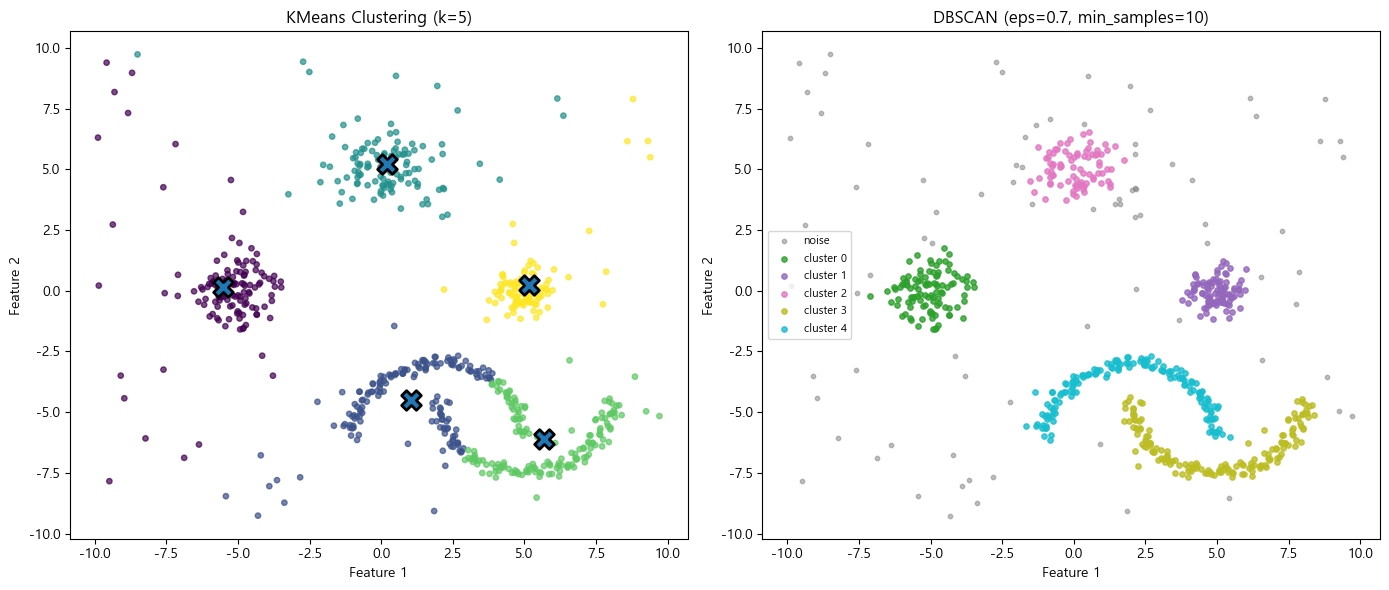

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, DBSCAN

# ---------------------------
# 1) 샘플 데이터 생성
# ---------------------------
# 둥근(cloud) 형태의 blob 3개
X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=[(-5, 0), (0, 5), (5, 0)],
    cluster_std=[0.8, 1.0, 0.5],
    random_state=42
)

# 휘어진 moon 2개
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)
# 위치 옮겨서 안 겹치게
X_moons[:, 0] = X_moons[:, 0] * 3 + 2
X_moons[:, 1] = X_moons[:, 1] * 3 - 6

# 랜덤 노이즈
rng = np.random.RandomState(42)
X_noise = rng.uniform(low=-10, high=10, size=(80, 2))

# 전체 데이터 합치기
X = np.vstack([X_blobs, X_moons, X_noise])

print("X shape:", X.shape)

# ---------------------------
# 2) KMeans / DBSCAN 학습
# ---------------------------
# KMeans: blob3 + moon2 = 5개라고 가정
kmeans = KMeans(n_clusters=5, random_state=42)
k_labels = kmeans.fit_predict(X)
k_centers = kmeans.cluster_centers_

# DBSCAN: eps, min_samples는 대략적인 값 (데이터에 따라 조정 가능)
dbscan = DBSCAN(eps=0.7, min_samples=10)
d_labels = dbscan.fit_predict(X)

print("KMeans 군집 수:", len(np.unique(k_labels)))
print("DBSCAN 군집 라벨:", np.unique(d_labels))
print("DBSCAN 노이즈 개수(label = -1):", np.sum(d_labels == -1))

# ---------------------------
# 3) 시각화
# ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- (1) KMeans 결과 ---
axes[0].scatter(X[:, 0], X[:, 1], c=k_labels, s=15, alpha=0.7)
axes[0].scatter(
    k_centers[:, 0], k_centers[:, 1],
    marker='X', s=200, linewidths=2, edgecolors='k'
)
axes[0].set_title("KMeans Clustering (k=5)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# --- (2) DBSCAN 결과 ---
# DBSCAN에서 -1은 노이즈니까 따로 색 지정
# 노이즈: 회색, 군집: colormap
unique_labels = np.unique(d_labels)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for lab, col in zip(unique_labels, colors):
    if lab == -1:
        # 노이즈
        col = (0.5, 0.5, 0.5, 0.5)  # 회색, 반투명
        mask = (d_labels == lab)
        axes[1].scatter(X[mask, 0], X[mask, 1], c=[col], s=10, label="noise")
    else:
        mask = (d_labels == lab)
        axes[1].scatter(X[mask, 0], X[mask, 1], c=[col], s=15, alpha=0.8, label=f"cluster {lab}")

axes[1].set_title(f"DBSCAN (eps=0.7, min_samples=10)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend(loc="best", fontsize=8)

plt.tight_layout()
plt.show()


# 차원축소

## PCA

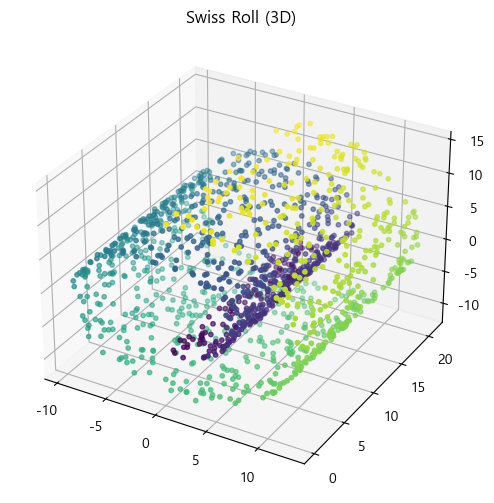

In [62]:
from sklearn.datasets import make_swiss_roll
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 데이터 생성
X, t = make_swiss_roll(
    n_samples=1500,
    noise=0.1,
    random_state=42
)

# 시각화 (3D)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:,0], X[:,1], X[:,2], c=t, cmap='viridis', s=10)
ax.set_title("Swiss Roll (3D)")
plt.show()


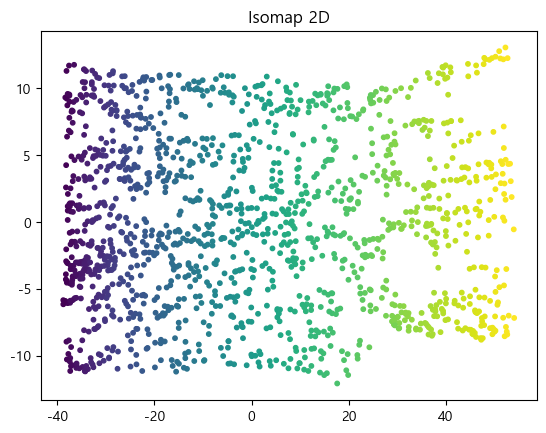

In [64]:
from sklearn.manifold import Isomap

isomap = Isomap(n_neighbors=10, n_components=2)
X_iso = isomap.fit_transform(X)

plt.scatter(X_iso[:,0], X_iso[:,1], c=t, cmap='viridis', s=10)
plt.title("Isomap 2D")
plt.show()


설명분산비율: [0.40727296 0.30616037 0.28656667]
총 설명분산: 1.0


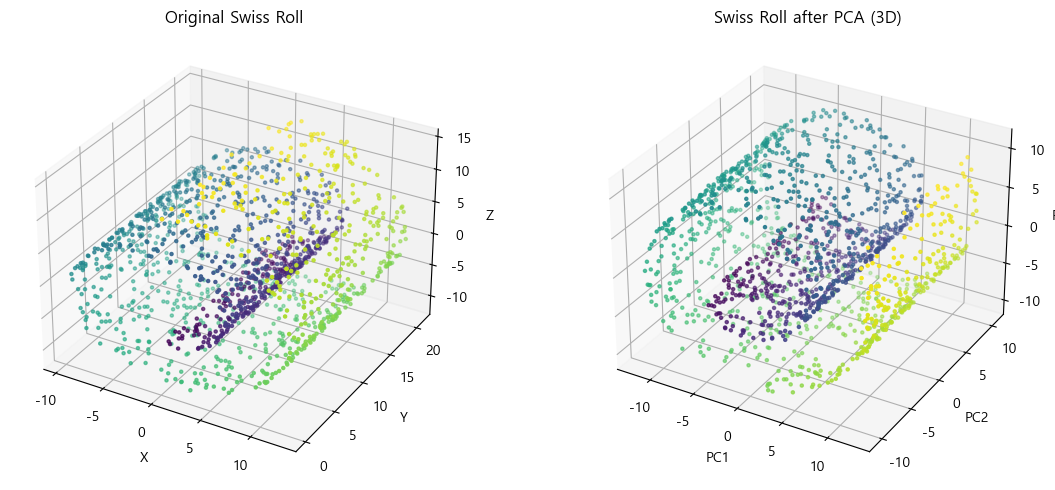

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA

# 1. 스위스롤 데이터 생성
X, t = make_swiss_roll(
    n_samples=1500,
    noise=0.1,
    random_state=42
)  # X.shape = (1500, 3)

# 2. PCA 3차원으로 수행
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

print("설명분산비율:", pca.explained_variance_ratio_)
print("총 설명분산:", pca.explained_variance_ratio_.sum())

# 3. 원본 vs PCA변환 결과 3D 시각화
fig = plt.figure(figsize=(12, 5))

# (1) 원본 스위스롤
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, s=5, cmap='viridis')
ax1.set_title("Original Swiss Roll")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# (2) PCA 3D 결과
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(X_pca[:, 0], X_pca[:, 2], X_pca[:, 1], c=t, s=5, cmap='viridis')
ax2.set_title("Swiss Roll after PCA (3D)")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_zlabel("PC3")

plt.tight_layout()
plt.show()
